Energy based onset detection

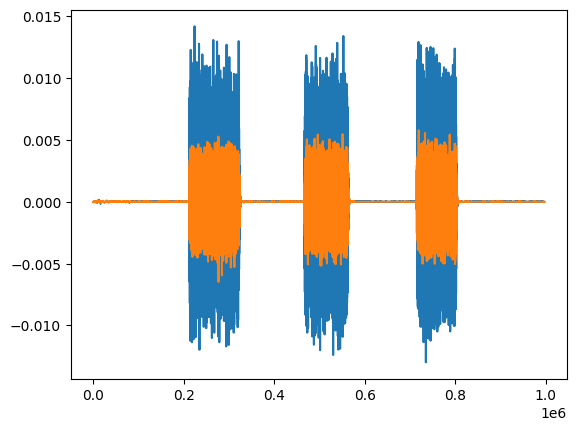

In [57]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

from HATS_Code.HATS_functions import fft_cross_correlation, woodworth_itd, itd_to_angle

PathToFiles = "Audio_Files/HATS/H2/-45"
dataL, fs = sf.read(f'{PathToFiles}/L.wav')

dataR, fs = sf.read(f'{PathToFiles}/R.wav')

L_click_idx = np.argmax(np.abs(dataL))
R_click_idx = np.argmax(np.abs(dataR))
    
click_offset = R_click_idx - L_click_idx 

L_Trimmed = dataL[L_click_idx + int(fs*2):]
R_Trimmed = dataR[R_click_idx + int(fs*2):]

min_len = min(len(L_Trimmed), len(R_Trimmed))
L_Trimmed = L_Trimmed[:min_len]
R_Trimmed = R_Trimmed[:min_len]

plt.plot(L_Trimmed)
plt.plot(R_Trimmed)


In [58]:
frame_length = 64

hop = 16

def find_onset_peak_based(data, threshold_frac=0.1):
    envelope = np.abs(data)
    peak = np.max(envelope)
    onset = np.argmax(envelope > peak * threshold_frac)
    return onset



energyL = np.array([
    np.sum(L_Trimmed[i:i+frame_length]**2)
    for i in range(0, len(L_Trimmed)-frame_length, hop)
])
noise_floorL = np.mean(energyL[:int(0.1*fs/hop)])
thresholdL = noise_floorL * 10
#onset_frameL = np.argmax(energyL > thresholdL)
#onset_sampleL = onset_L * hop
onset_L = find_onset_peak_based(L_Trimmed)
onset_sampleL = onset_L


energyR = np.array([
    np.sum(R_Trimmed[i:i+frame_length]**2)
    for i in range(0, len(R_Trimmed)-frame_length, hop)
])
noise_floorR = np.mean(energyR[:int(0.1*fs/hop)])
thresholdR = noise_floorR * 10
#onset_frameR = np.argmax(energyR > thresholdR)
#onset_sampleR = onset_R * hop
onset_R = find_onset_peak_based(R_Trimmed)
onset_sampleR = onset_R


print(f"Onset at sample {onset_sampleL} ({onset_sampleL/fs:.3f}s)")
print(f"Onset at sample {onset_sampleR} ({onset_sampleR/fs:.3f}s)")

Onset at sample 211915 (4.415s)
Onset at sample 211929 (4.415s)


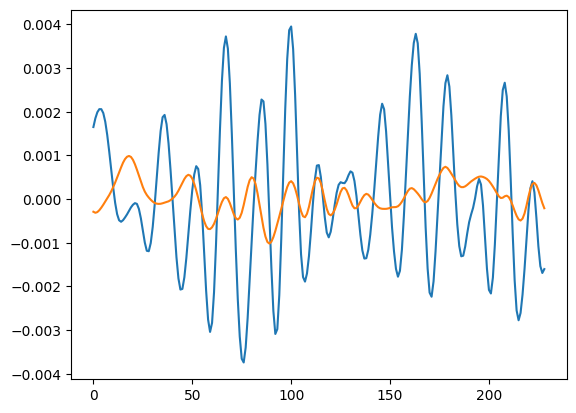

In [ ]:
#window_length_samples = 48000000
window_length_samples = 229
#window_length_samples = 92

onset = min(onset_L, onset_R)

L_windowed = L_Trimmed[onset : onset + window_length_samples]
R_windowed = R_Trimmed[onset : onset + window_length_samples]

plt.plot(L_windowed)
plt.plot(R_windowed)



In [60]:
d = 0.21
c = 343
r = 0.0875 
angle = -45

correlation = fft_cross_correlation(L_windowed, R_windowed)

n = len(L_windowed)
lags = np.arange(-n//2, n//2)
lags = lags[:len(correlation)]

max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
itd_samples = lags[mask][np.argmax(correlation[mask])]
itd_seconds = itd_samples / fs
        
angle_deg = itd_to_angle(itd_seconds, r, fs)
print(angle_deg)

itd_expected = woodworth_itd(float(angle), r)
print("Diff ", itd_expected-itd_seconds)

-36.28198988155194
Diff  -6.824105729183558e-05
